# 0.기본 설정

## 글자 폰트 설정

In [ ]:
# 나눔고딕 폰트 설치
!apt-get update -qq
!apt-get install -y fonts-nanum


# Matplotlib 폰트 설정
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
import matplotlib


# 나눔고딕 폰트 경로 설정
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_manager.fontManager.addfont(font_path)
rc('font', family='NanumGothic', size=12)


# 마이너스 폰트 깨짐 방지
matplotlib.rcParams['axes.unicode_minus'] = False


print("폰트 설정 완료 - NanumGothic 적용됨")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 119 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (70.9 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
폰트 설정 완료 - NanumGothic 적용됨


## 필요 라이브러리 설치

In [ ]:
# 필요 라이브러리 설치

!pip install torchviz | tail -n 1
!pip install torchinfo | tail -n 1
!apt install tree -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  tree
0 upgraded, 1 newly installed, 0 to remove and 119 not upgraded.
Need to get 47.4 kB of archives.
After this operation, 111 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 tree amd64 2.1.1-2ubuntu3.24.04.2 [47.4 kB]
Fetched 47.4 kB in 0s (1,423 kB/s)
Selecting previously unselected package tree.
(Reading database ... 127345 files and directories currently installed.)
Preparing to unpack .../tree_2.1.1-2ubuntu3.24.04.2_amd64.deb ...
Unpacking tree (2.1.1-2ubuntu3.24.04.2) ...
Setting up tree (2.1.1-2ubuntu3.24.04.2) ...
Processing triggers for man-db (2.12.0-4build2) ...


## 라이브러리 불러오기

In [ ]:
# 라이브러리 임포트

%matplotlib inline
import os
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from torchinfo import summary
from torchvision import transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
from torchviz import make_dot
import zipfile
from torchvision import models

# optimizer로 SGD(확률적 경사 하강법)을 사용
import torch.optim as optim

# 폰트 관련 용도
import matplotlib.font_manager as fm

# 나눔 고딕 폰트의 경로 명시
path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
font_name = fm.FontProperties(fname=path, size=10).get_name()

## matplotlib의 그래프관련 설정

In [ ]:
# 기본 폰트 설정
plt.rcParams['font.family'] = font_name

# 기본 폰트 사이즈 변경
plt.rcParams['font.size'] = 14

# 기본 그래프 사이즈 변경
plt.rcParams['figure.figsize'] = (6,6)

# 기본 그리드 표시
# 필요에 따라 설정할 때는, plt.grid()
plt.rcParams['axes.grid'] = True

# 마이너스 기호 정상 출력
plt.rcParams['axes.unicode_minus'] = False

# 넘파이 부동소수점 자릿수 표시
np.set_printoptions(suppress=True, precision=4)

## GPU 사용가능 여부에 따른 장치설정

In [ ]:
## GPU 사용가능 여부에 따른 장치지정
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'현재 사용중인 장치 : {device}')

현재 사용중인 장치 : cuda:0


## 구글 드라이브 연결

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1.공통함수 불러오기

In [ ]:
## github로 부터 라이브러리 다운로드
!git clone https://github.com/wolfmancool/Deep_Learning

## 모든 사용자 정의 함수 불러오기
from Deep_Learning.common_function import *

## 사용자 정의 함수 확인
print(README)

Cloning into 'Deep_Learning'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 53 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 24.69 KiB | 2.06 MiB/s, done.
Resolving deltas: 100% (13/13), done.
1. save_checkpoint : 체크 포인트 저장 함수
기능 : 학습 중인 모델, Optimizer, Epoch, history 드라이브에 저장

2. save_history : history 저장 함수
기능 : 최종 학습이 끝나고 history를 드라이브에 저장

3. fit : 학습 함수
기능 : 
학습 데이터셋을 이용한 훈련, 손실, 정확도 출력
검증 데이터셋을 이용한 훈련, 손실, 정확도 출력
체크포인트 저장, 최종 history 저장

4. evaluate_history : 학습곡선 출력함수
기능 : history를 이용해 학습곡선(손실, 정확도) 출력 및 저장

5. show_images_labels : 예측 결과 표시 이미지 출력 함수
기능 : 첫 미니배치의 50개의 데이터 샘플에 대해 예측결과와 label과 함께 이미지위에 표시

6. torch_seed : 난수 고정 함수
기능 : 파이토치 난수 고정

7. calculation_graph : 손실 계산 그래프 시각화 함수
기능 : 계산 그래프를 시각화 및 저장

8. load_history : 드라이브에 저장된 history불러오는 함수
기능 : 드라이브에 저장된 history를 불러오기

9. load_checkpoint : 체크포인트 불러오기 함수
기능 : 저장된 모델, Optimizer,

# 2.데이터 준비

## 2-1.전처리과정 정의

In [ ]:
# 전처리과정 인스턴스 생성
dataset_transforms = transforms.Compose([
    # 전처리1 :
    ## 텐서로 변환
    ## 정규화 : 픽셀값을 [0, 255]에서 [0, 1]로 변환
    transforms.ToTensor(),

    # 전처리2 : 정규화 => 픽셀값을 [0, 1]에서 [-1, 1]로 변환
    transforms.Normalize(0.5, 0.5)
])

## 2-2.데이터셋 불러오기

In [ ]:
# 데이터셋을 저장할 디렉토리 경로 설정
save_dataset_path = os.path.join('/content/drive/MyDrive/Study/DeepLearning/Project', 'dataset')

# 해당 디렉토리가 없는 경우 생성
os.makedirs(save_dataset_path, exist_ok=True)

# 훈련 데이터셋 불러오기
train_dataset = datasets.MNIST(
    root=save_dataset_path, train=True, transform=dataset_transforms, download=True
)

# 검증 데이터셋 불러오기
val_dataset = datasets.MNIST(
    root=save_dataset_path, train=False, transform=dataset_transforms, download=True
)


## 2-3.데이터로더 생성

In [ ]:
# 데이터로더를 이용한 데이터셋을 미니배치로 분할

# 배치사이즈 설정
batch_size = 500

# 학습 데이터로더 생성
train_dataloader = DataLoader(
    dataset=train_dataset, batch_size=batch_size, shuffle=True
)

# 검증 데이터로더 생성
val_dataloader = DataLoader(
    dataset=val_dataset, batch_size=batch_size, shuffle=False
)

# 3.모델 정의

## 3-1.모델 클래스 정의

In [ ]:
# 모델 클래스 정의
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    # 각 layer 인스턴스 생성
    ## convolutoin layer 인스턴스 생성
    self.cv1 = nn.Conv2d(1, 32, 3, padding=1)
    self.cv2 = nn.Conv2d(32, 64, 3, padding=1)
    self.cv3 = nn.Conv2d(64, 128, 3, padding=1)

    ## Activation layer 인스턴스 생성
    self.relu = nn.ReLU(inplace=True)

    ## pooling layer 인스턴스 생성
    self.maxpool = nn.MaxPool2d(2)

    ## flatten layer 인스턴스 생성
    self.flatten = nn.Flatten()

    ## linear layer 인스턴스 생성
    self.l1 = nn.Linear(128*7*7, 256)
    self.l2 = nn.Linear(256, 128)
    self.l3 = nn.Linear(128, 10)

    ## dropout layer 인스턴스 생성
    self.dropout = nn.Dropout(p=0.3)


    # feature extractor 인스턴스 생성
    self.feature_extractor = nn.Sequential(
        self.cv1,
        self.relu,
        self.maxpool,

        self.cv2,
        self.relu,
        self.maxpool,

        self.cv3,
        self.relu
    )

    # classifier 인스턴스 생성
    self.classifier = nn.Sequential(
        self.flatten,

        self.l1,
        self.relu,
        self.dropout,

        self.l2,
        self.relu,

        self.l3
    )

  # forward propagation 메서드 정의
  def forward(self, inputs):
    x = self.feature_extractor(inputs)
    x = self.classifier(x)

    return x

## 3-2.모델, 최적화함수, 손실함수 인스턴스 생성

In [ ]:
# 모델 인스턴스 생성 및 연산위치를 GPU로 이동
model = Model().to(device)

# 최적화함수 인스턴스 생성 : SGD
optimizer = optim.SGD(params=model.parameters(), lr=0.01, momentum=0.9)

# 손실함수 인스턴스 생성 : CrossLossEntropy
criterion = nn.CrossEntropyLoss()

## 3-3.모델 확인

In [ ]:
print(model)

Model(
  (cv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (cv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (cv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (l1): Linear(in_features=6272, out_features=256, bias=True)
  (l2): Linear(in_features=256, out_features=128, bias=True)
  (l3): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (feature_extractor): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, 

In [ ]:
summary(model, (1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 7, 7]            92,352
│    └─Conv2d: 2-1                       [1, 32, 28, 28]           320
├─Sequential: 1-6                        --                        (recursive)
│    └─ReLU: 2-2                         [1, 32, 28, 28]           --
├─Sequential: 1-5                        --                        (recursive)
│    └─MaxPool2d: 2-3                    [1, 32, 14, 14]           --
│    └─Conv2d: 2-4                       [1, 64, 14, 14]           18,496
├─Sequential: 1-6                        --                        (recursive)
│    └─ReLU: 2-5                         [1, 64, 14, 14]           --
├─Sequential: 1-5                        --                        (recursive)
│    └─MaxPool2d: 2-6                    [1, 64, 7, 7]             --
│    └─Conv2d: 2-7                      

# 4.학습

In [ ]:
# 학습횟수 설정
num_epochs = 5

# 기본 저장경로 설정
base_path = r'/content/drive/MyDrive/Study/DeepLearning/Project/MNIST_Classification'

# history 초기값 설정 (에러 방지용)
history = np.zeros((0, 5))

# checkpoint 디렉토리 경로 설정
checkpoint_dir = os.path.join(base_path, 'checkpoint')

# 최근 학습중인 체크포인트가 있으면 불러오고 없으면 초기화된 history 이용
if os.path.isdir(checkpoint_dir) and len(os.listdir(checkpoint_dir)) > 0:
    print('학습 중단된 checkpoint가 존재합니다.')
    try:
        # 사용자 입력을 직접 받거나, 가장 최신 파일을 자동으로 선택하도록 구성할 수 있습니다.
        checkpoint_path = input('불러오려는 checkpoint 파일 경로 : ')
        if checkpoint_path.strip():
            model, optimizer, epoch, history = load_checkpoint(model, optimizer, checkpoint_path, device)
            print(f'{epoch} epoch 체크포인트 불러오기 완료')
        else:
            print('입력이 없어 처음부터 학습을 시작합니다.')
    except Exception as e:
        print(f'체크포인트 로드 중 오류 발생 ({e}). 처음부터 학습을 시작합니다.')
else:
    print('저장된 체크포인트가 없습니다. history를 초기화합니다.')

# 학습 시작
fit(model, optimizer, criterion, num_epochs, train_dataloader, val_dataloader,
    device, history, base_path, save_interval=5)

학습 중단된 checkpoint가 존재합니다.
불러오려는 checkpoint 파일 경로 : /content/drive/MyDrive/Study/DeepLearning/Project/MNIST_Classification/checkpoint/checkpoint_20261124_054055_Epoch25.pth
체크포인트 불러오기 완료 : 25 Epoch까지 학습됨
25 epoch 체크포인트 불러오기 완료


  0%|          | 0/120 [00:00<?, ?it/s]

Epoch [26/30], train_loss: 3.424174279207364e-05, train_acc: 0.9949166666666667, val_loss: 4.487026808783412e-05, val_acc: 0.9921


  0%|          | 0/120 [00:00<?, ?it/s]

Epoch [27/30], train_loss: 3.3742806625862915e-05, train_acc: 0.9947166666666667, val_loss: 4.652163361897692e-05, val_acc: 0.9922


  0%|          | 0/120 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch [29/30], train_loss: 3.046371379556755e-05, train_acc: 0.9952, val_loss: 4.597659072023816e-05, val_acc: 0.9924


  0%|          | 0/120 [00:00<?, ?it/s]

Epoch [30/30], train_loss: 2.8314848492542903e-05, train_acc: 0.9955166666666667, val_loss: 4.683405316900462e-05, val_acc: 0.9918
체크포인트 저장 완료 : /content/drive/MyDrive/Study/DeepLearning/Project/MNIST_Classification/checkpoint/checkpoint_20261124_054844_Epoch30.pth
최종 history 저장 완료 : /content/drive/MyDrive/Study/DeepLearning/Project/MNIST_Classification/history/history20261124_054844


array([[ 1.    ,  0.0042,  0.3425,  0.0015,  0.7727],
       [ 2.    ,  0.0008,  0.8744,  0.0004,  0.936 ],
       [ 3.    ,  0.0004,  0.9456,  0.0002,  0.9665],
       [ 4.    ,  0.0002,  0.9633,  0.0001,  0.976 ],
       [ 5.    ,  0.0002,  0.9716,  0.0001,  0.979 ],
       [ 6.    ,  0.0002,  0.9754,  0.0001,  0.9845],
       [ 7.    ,  0.0001,  0.9789,  0.0001,  0.9857],
       [ 8.    ,  0.0001,  0.9816,  0.0001,  0.9864],
       [ 9.    ,  0.0001,  0.9845,  0.0001,  0.9882],
       [10.    ,  0.0001,  0.9849,  0.0001,  0.988 ],
       [11.    ,  0.0001,  0.9868,  0.0001,  0.9877],
       [12.    ,  0.0001,  0.9877,  0.0001,  0.9883],
       [13.    ,  0.0001,  0.988 ,  0.0001,  0.9897],
       [14.    ,  0.0001,  0.9889,  0.0001,  0.99  ],
       [15.    ,  0.0001,  0.9899,  0.0001,  0.9908],
       [16.    ,  0.0001,  0.9906,  0.0001,  0.9891],
       [17.    ,  0.0001,  0.99  ,  0.0001,  0.9913],
       [18.    ,  0.0001,  0.9913,  0.0001,  0.9902],
       [19.    ,  0.0001,  0

# 5.결과 분석

불러오려는 checkpoint 파일 경로 : /content/drive/MyDrive/Study/DeepLearning/Project/MNIST_Classification/checkpoint/checkpoint_20261124_054844_Epoch30.pth
체크포인트 불러오기 완료 : 30 Epoch까지 학습됨
초기상태 => 검증손실 : 0.00149 검증정확도 : 0.77270
최종상태 => 검증손실 : 0.00005 검증정확도 : 0.99180


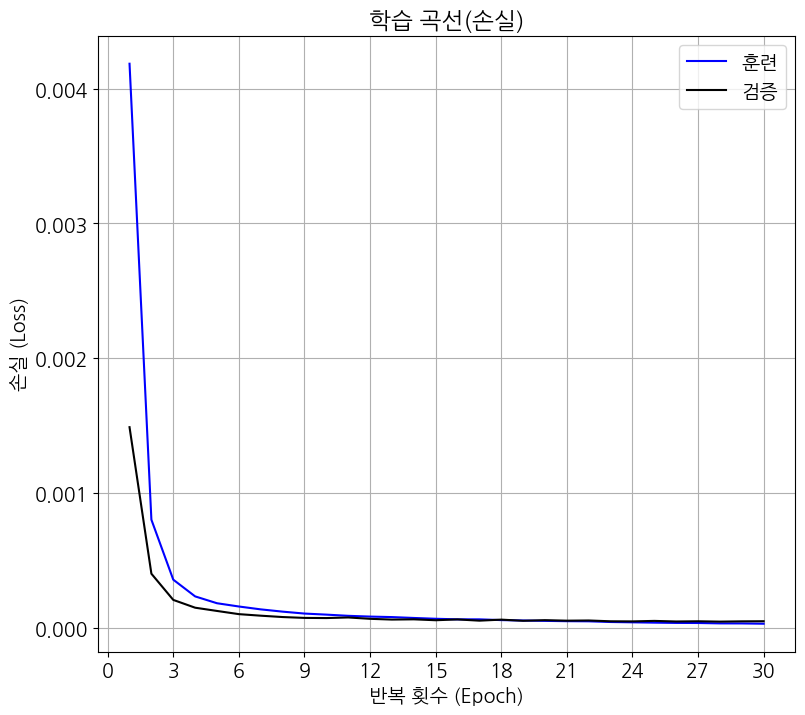

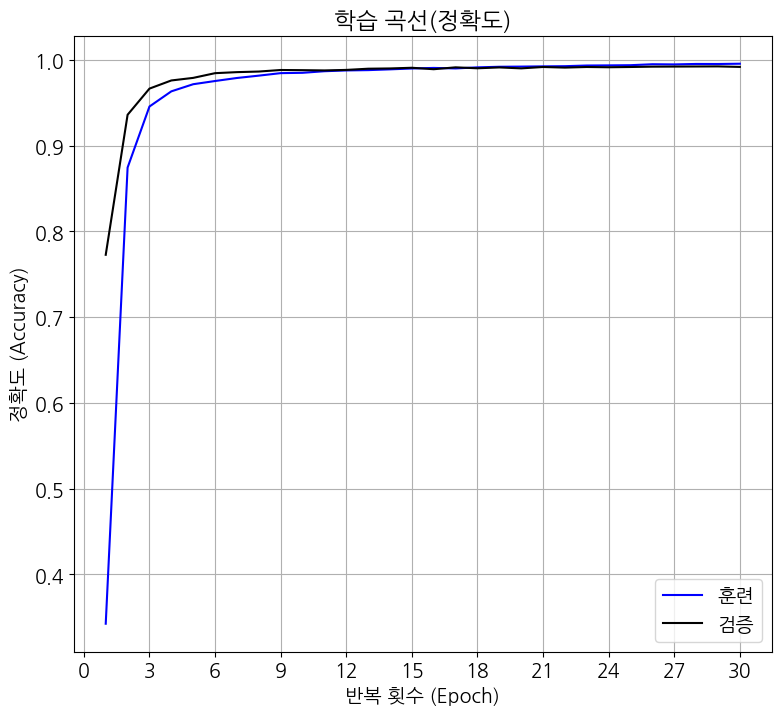

In [ ]:
# 불러오려는 체크포인트 파일 경로 설정
checkpoint_path = input('불러오려는 checkpoint 파일 경로 : ')

# 체크포인트 불러오기
model, optimizer, epoch, history = load_checkpoint(model, optimizer, checkpoint_path, device)

# 학습곡선 출력
evaluate_history(history, base_path)

In [ ]:
show